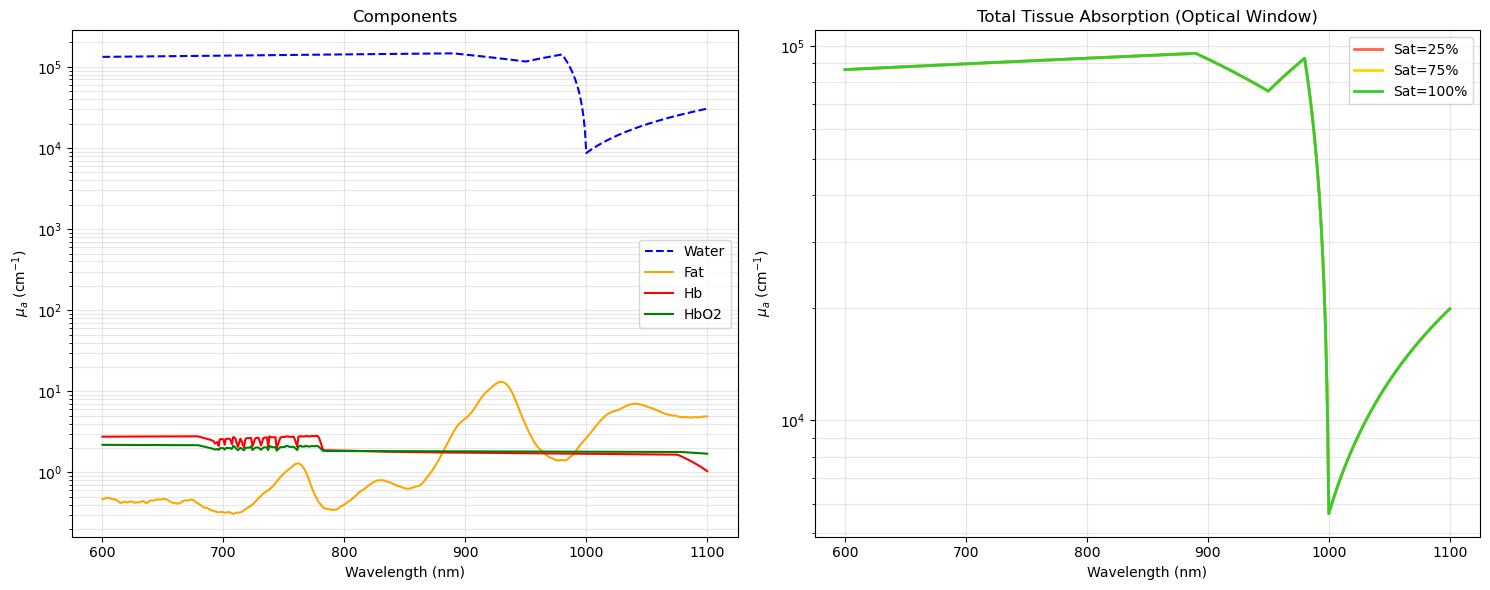

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import requests
import re
import io

# Wavelength grid (optical window)
wl = np.arange(600, 1101, 1)
SCI_NUMBER_PATTERN = r"[-+]?\d*\.?\d+(?:[eEdD][-+]?\d+)?"
DATA_DIR = "spectra_csv"
os.makedirs(DATA_DIR, exist_ok=True)

def save_csv(path, header, array):
    np.savetxt(path, array, delimiter=",", header=header, comments="")

def parse_water_hale73_to_csv():
    url = "https://omlc.org/spectra/water/data/hale73.txt"
    txt = requests.get(url).text.replace('D','E').replace('d','e')
    nums = np.array(re.findall(SCI_NUMBER_PATTERN, txt), dtype=float)
    triples = nums[: (nums.size // 3) * 3].reshape(-1, 3)
    wl_um = triples[:, 0]
    k_val = triples[:, 2]
    order = np.argsort(wl_um)
    wl_um = wl_um[order]
    k_val = k_val[order]
    wl_nm = wl_um * 1000.0
    mu_a = 4 * np.pi * k_val / (wl_nm * 1e-7)  # lambda in cm
    out = np.column_stack([wl_nm, mu_a, k_val])
    path = os.path.join(DATA_DIR, "water_hale73.csv")
    save_csv(path, "wavelength_nm,mu_a_cm^-1,k", out)
    return path

def parse_fat_to_csv():
    txt = requests.get("https://omlc.org/spectra/fat/fat.txt").text
    arr = np.genfromtxt(io.StringIO(txt), comments="#")
    arr = arr[~np.isnan(arr).any(axis=1)]
    wl_nm = arr[:, 0]
    mu_a = arr[:, 1]
    out = np.column_stack([wl_nm, mu_a])
    path = os.path.join(DATA_DIR, "fat.csv")
    save_csv(path, "wavelength_nm,mu_a_cm^-1", out)
    return path

def parse_hb_summary_to_csv():
    html = requests.get("https://omlc.org/spectra/hemoglobin/summary.html").text
    nums = np.array(re.findall(SCI_NUMBER_PATTERN, html), dtype=float)
    triples = nums[: (nums.size // 3) * 3].reshape(-1, 3)
    wl_nm = triples[:, 0]
    eps_hbo2 = triples[:, 1]  # cm^-1/M
    eps_hb = triples[:, 2]   # cm^-1/M
    order = np.argsort(wl_nm)
    wl_nm = wl_nm[order]
    eps_hbo2 = eps_hbo2[order]
    eps_hb = eps_hb[order]
    out = np.column_stack([wl_nm, eps_hbo2, eps_hb])
    path = os.path.join(DATA_DIR, "hemoglobin_summary.csv")
    save_csv(path, "wavelength_nm,eps_hbo2_cm^-1_per_M,eps_hb_cm^-1_per_M", out)
    return path

# Create CSVs (overwrite each run to keep consistent)
water_csv = parse_water_hale73_to_csv()
fat_csv = parse_fat_to_csv()
hb_csv = parse_hb_summary_to_csv()

# Load from CSVs
water_arr = np.loadtxt(water_csv, delimiter=",", skiprows=1)
fat_arr = np.loadtxt(fat_csv, delimiter=",", skiprows=1)
hb_arr = np.loadtxt(hb_csv, delimiter=",", skiprows=1)

w_wl_nm, mu_a_water_raw = water_arr[:, 0], water_arr[:, 1]
f_wl, mu_a_fat_raw = fat_arr[:, 0], fat_arr[:, 1]
h_wl, eps_hbo2_raw, eps_hb_raw = hb_arr[:, 0], hb_arr[:, 1], hb_arr[:, 2]

# Interpolate to wl grid
mu_a_water = np.interp(wl, w_wl_nm, mu_a_water_raw)
mu_a_fat = np.interp(wl, f_wl, mu_a_fat_raw)
eps_hbo2 = np.interp(wl, h_wl, eps_hbo2_raw)
eps_hb = np.interp(wl, h_wl, eps_hb_raw)

# Mixing coefficients
V_WATER, V_FAT, V_BLOOD = 0.65, 0.15, 0.20
C_HB_BLOOD = 2.3e-3  # M

def get_tissue_mu_a(oxygen_sat):
    mu_a_hbo2 = eps_hbo2 * C_HB_BLOOD
    mu_a_hb = eps_hb * C_HB_BLOOD
    mu_a_blood_total = oxygen_sat * mu_a_hbo2 + (1 - oxygen_sat) * mu_a_hb
    return V_WATER * mu_a_water + V_FAT * mu_a_fat + V_BLOOD * mu_a_blood_total

# --- PLOTTING ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.semilogy(wl, mu_a_water, 'b--', label='Water')
ax1.semilogy(wl, mu_a_fat, color='orange', label='Fat')
ax1.semilogy(wl, eps_hb * C_HB_BLOOD, 'r', label='Hb')
ax1.semilogy(wl, eps_hbo2 * C_HB_BLOOD, 'g', label='HbO2')
ax1.set_title("Components")
ax1.set_xlabel("Wavelength (nm)")
ax1.set_ylabel(r"$\mu_a$ (cm$^{-1}$)")
ax1.legend()
ax1.grid(True, alpha=0.3, which='both')

for sat, col in zip([0.25, 0.75, 1.0], ['tomato', 'gold', 'limegreen']):
    ax2.plot(wl, get_tissue_mu_a(sat), label=f'Sat={sat*100:.0f}%', color=col, linewidth=2)

ax2.set_yscale('log')
ax2.set_title("Total Tissue Absorption (Optical Window)")
ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel(r"$\mu_a$ (cm$^{-1}$)")
ax2.grid(True, which='both', alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

In [3]:
## Optical Properties of Biological Tissues 
## Light Propagation Model
## Exercise 1.2 & 1.3: Build FDM solver

def solve_DA_1d(k2_vec, dx, s_vec, D):
    """
    Solve the 1D Diffusion Approximation using Finite Differences Method.
    
    Parameters:
    -----------
    k2_vec :  array of size n
        Values of k^2(x) = mu_a(x) / D at each point
    dx : float
        Discretization spacing
    s_vec : array of size n
        Source term s(x) at each point
    D : float
        Diffusion coefficient (assumed homogeneous)
    
    Returns:
    --------
    phi : array of size n
        Fluence at each point
    """
    n = len(k2_vec)
    A = np.zeros((n, n))
    b = s_vec / D  # Right-hand side
    
    # Boundary conditions:  EBC means phi[0] = 0 and phi[n-1] = 0
    A[0, 0] = 1.0
    b[0] = 0.0
    
    A[n-1, n-1] = 1.0
    b[n-1] = 0.0
    
    # Interior points:  -d²phi/dx² + k²phi = s/D
    # Using central difference for 2nd derivative: 
    # (phi[i-1] - 2*phi[i] + phi[i+1])/dx² + k²[i]*phi[i] = s[i]/D
    for i in range(1, n-1):
        A[i, i-1] = -1.0 / (dx**2)
        A[i, i]   =  2.0 / (dx**2) + k2_vec[i]
        A[i, i+1] = -1.0 / (dx**2)
    
    # Solve the system
    phi = np.linalg.solve(A, b)
    return phi




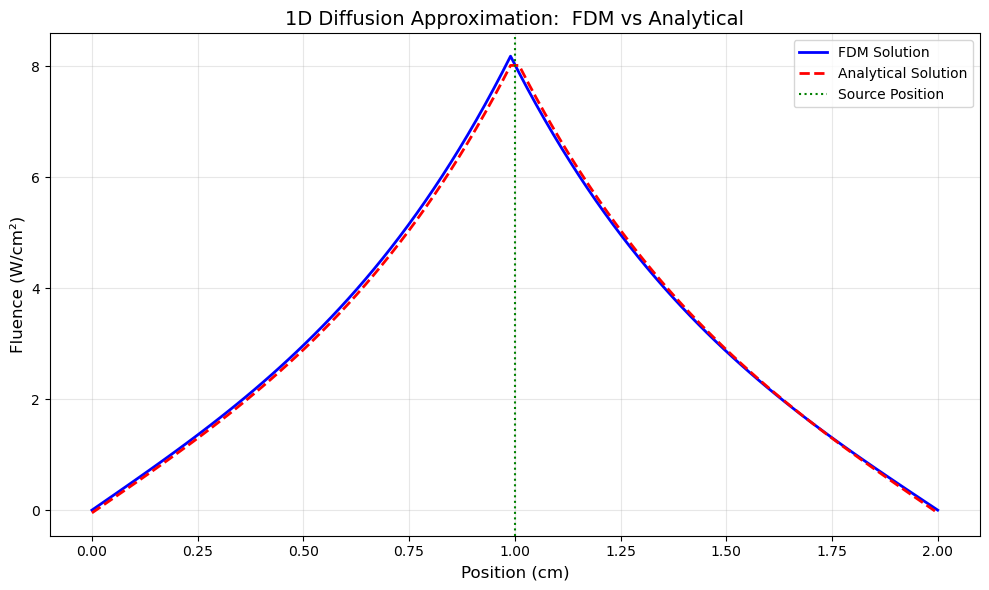

Max relative error: 2.08%


In [4]:
## Exercise 1.4: Compare with analytical solution

# Setup domain
L = 2.0  # 2 cm
n = 100  # Use more points for better accuracy
dx = L / (n - 1)
x = np.linspace(0, L, n)

# Optical properties (using values from the problem)
mu_s = 100.0  # cm^-1
g = 0.9
n_refr = 1.37

# Choose a wavelength and get mu_a from your tissue model
# Let's use 800 nm as an example (you can change this)
wavelength = 800  # nm
oxygen_sat = 0.75  # 75% oxygenation

# Get mu_a at this wavelength (you need to adapt this to use your Exercise 1.1 code)
# For demonstration, let's use a typical value: 
mu_a = 0.1  # cm^-1 (you should calculate this from your tissue model)

# Calculate diffusion coefficient
D = 1.0 / (3.0 * (mu_a + (1 - g) * mu_s))

# Calculate k²
k2_vec = np.ones(n) * (mu_a / D)
k = np.sqrt(mu_a / D)

# Create source:  delta function at x = 1 cm
source_position = 1.0  # cm
source_power = 1.0  # W/cm²
s_vec = np.zeros(n)
source_idx = np.argmin(np.abs(x - source_position))
s_vec[source_idx] = source_power / dx  # Discretized delta function

# Solve using FDM
phi_fdm = solve_DA_1d(k2_vec, dx, s_vec, D)

# Analytical solution using Green's function with method of images
def analytical_solution_1d(x, x_source, L, k, D, source_power):
    """
    Analytical solution for 1D slab with EBC using method of images.
    For simplicity, we'll use a few image sources.
    """
    phi = np.zeros_like(x)
    
    # Main source
    r = np.abs(x - x_source)
    phi += (source_power / (2 * k * D)) * np.exp(-k * r)
    
    # Image sources (add several to approximate EBC)
    # Images at positions mirrored about boundaries
    for m in range(-3, 4):  # Use several images
        if m == 0:
            continue
        # Left boundary images
        x_image = -x_source + 2 * m * L
        r = np.abs(x - x_image)
        phi -= (source_power / (2 * k * D)) * np.exp(-k * r)
        
        # Right boundary images
        x_image = 2 * L - x_source + 2 * m * L
        r = np.abs(x - x_image)
        phi -= (source_power / (2 * k * D)) * np.exp(-k * r)
    
    return phi

phi_analytical = analytical_solution_1d(x, source_position, L, k, D, source_power)

# Plot comparison
plt.figure(figsize=(10, 6))
plt.plot(x, phi_fdm, 'b-', linewidth=2, label='FDM Solution')
plt.plot(x, phi_analytical, 'r--', linewidth=2, label='Analytical Solution')
plt.axvline(source_position, color='g', linestyle=':', label='Source Position')
plt.xlabel('Position (cm)', fontsize=12)
plt.ylabel('Fluence (W/cm²)', fontsize=12)
plt.title('1D Diffusion Approximation:  FDM vs Analytical', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Max relative error: {np.max(np.abs(phi_fdm - phi_analytical) / np.max(phi_analytical)) * 100:.2f}%")




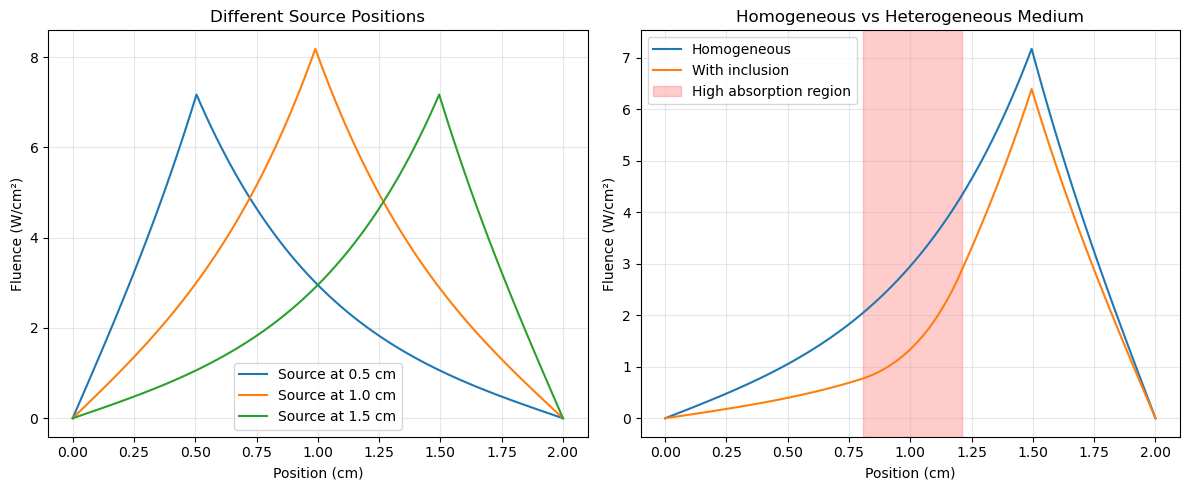

In [5]:
## Exercise 1.5: Different source positions and non-homogeneous k²

plt.figure(figsize=(12, 5))

# Test 1: Different source positions
plt.subplot(1, 2, 1)
for src_pos in [0.5, 1.0, 1.5]:
    s_vec = np.zeros(n)
    source_idx = np.argmin(np.abs(x - src_pos))
    s_vec[source_idx] = source_power / dx
    phi = solve_DA_1d(k2_vec, dx, s_vec, D)
    plt.plot(x, phi, label=f'Source at {src_pos} cm')

plt.xlabel('Position (cm)')
plt.ylabel('Fluence (W/cm²)')
plt.title('Different Source Positions')
plt.legend()
plt.grid(True, alpha=0.3)

# Test 2: Non-homogeneous absorption (e.g., inclusion in the middle)
plt.subplot(1, 2, 2)

# Create heterogeneous medium with higher absorption in center
mu_a_vec = np.ones(n) * 0.1
mu_a_vec[int(n*0.4):int(n*0.6)] = 0.5  # Higher absorption in center region
k2_vec_hetero = mu_a_vec / D

s_vec = np.zeros(n)
s_vec[source_idx] = source_power / dx

phi_homo = solve_DA_1d(np.ones(n) * (0.1 / D), dx, s_vec, D)
phi_hetero = solve_DA_1d(k2_vec_hetero, dx, s_vec, D)

plt.plot(x, phi_homo, label='Homogeneous')
plt.plot(x, phi_hetero, label='With inclusion')
plt.axvspan(x[int(n*0.4)], x[int(n*0.6)], alpha=0.2, color='red', label='High absorption region')
plt.xlabel('Position (cm)')
plt.ylabel('Fluence (W/cm²)')
plt.title('Homogeneous vs Heterogeneous Medium')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()




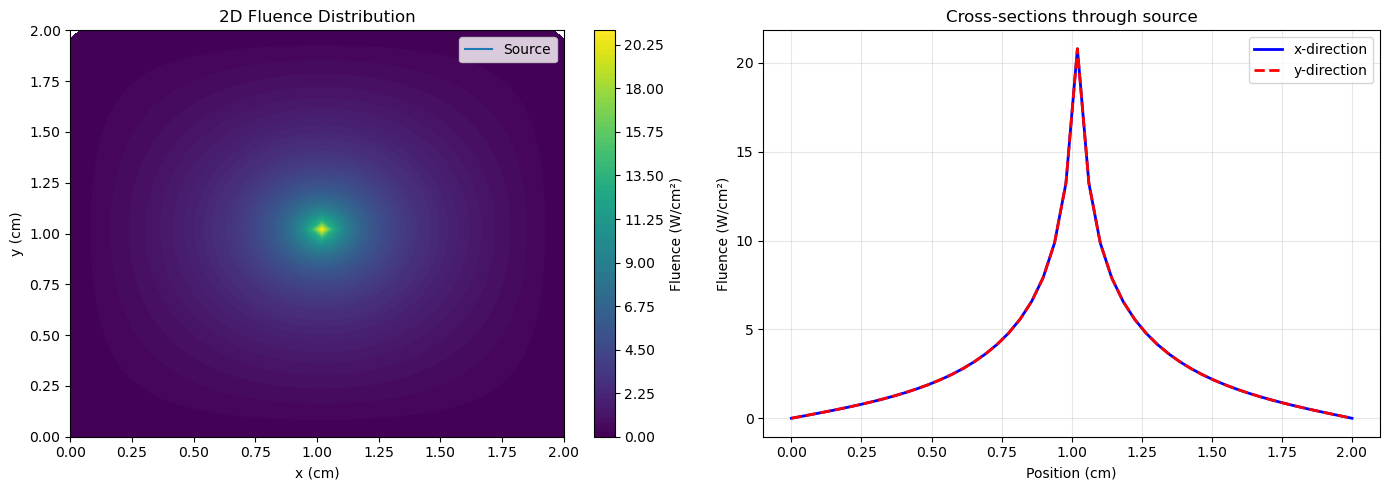

2D solver completed successfully!


In [6]:
## Exercise 1.6 & 1.7: 2D FDM Solver

def solve_DA_2d(k2_matrix, dx, s_matrix, D):
    """
    Solve the 2D Diffusion Approximation using Finite Differences Method.
    
    Parameters:
    -----------
    k2_matrix : array of shape (nx, ny)
        Values of k²(x,y) at each point
    dx : float
        Discretization spacing (assumed same in x and y)
    s_matrix : array of shape (nx, ny)
        Source term s(x,y) at each point
    D : float
        Diffusion coefficient
    
    Returns:
    --------
    phi_matrix : array of shape (nx, ny)
        Fluence at each point
    """
    nx, ny = k2_matrix. shape
    n_total = nx * ny
    
    # Create matrix A and vector b
    A = np.zeros((n_total, n_total))
    b = s_matrix.ravel() / D
    
    # Helper function to convert 2D indices to 1D
    def idx(i, j):
        return i * ny + j
    
    # Fill the matrix
    for i in range(nx):
        for j in range(ny):
            current_idx = idx(i, j)
            
            # Boundary conditions:  EBC (phi = 0 at boundaries)
            if i == 0 or i == nx-1 or j == 0 or j == ny-1:
                A[current_idx, current_idx] = 1.0
                b[current_idx] = 0.0
            else:
                # Interior point: -∇²phi + k²phi = s/D
                # Each interior point has 4 neighbors
                
                # Center point coefficient
                A[current_idx, current_idx] = 4.0 / (dx**2) + k2_matrix[i, j]
                
                # Left neighbor (i, j-1)
                A[current_idx, idx(i, j-1)] = -1.0 / (dx**2)
                
                # Right neighbor (i, j+1)
                A[current_idx, idx(i, j+1)] = -1.0 / (dx**2)
                
                # Bottom neighbor (i-1, j)
                A[current_idx, idx(i-1, j)] = -1.0 / (dx**2)
                
                # Top neighbor (i+1, j)
                A[current_idx, idx(i+1, j)] = -1.0 / (dx**2)
    
    # Solve the system
    phi_vec = np.linalg.solve(A, b)
    
    # Reshape back to 2D
    phi_matrix = phi_vec.reshape(nx, ny)
    return phi_matrix


## Test the 2D solver

# Setup 2D domain
Lx, Ly = 2.0, 2.0  # cm
nx, ny = 50, 50
dx = Lx / (nx - 1)
x_2d = np.linspace(0, Lx, nx)
y_2d = np.linspace(0, Ly, ny)
X, Y = np.meshgrid(x_2d, y_2d, indexing='ij')

# Optical properties (same as before)
k2_matrix = np.ones((nx, ny)) * (mu_a / D)

# Create point source at center
s_matrix = np.zeros((nx, ny))
source_i, source_j = nx // 2, ny // 2
s_matrix[source_i, source_j] = source_power / (dx**2)  # 2D delta function

# Solve
phi_2d = solve_DA_2d(k2_matrix, dx, s_matrix, D)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Contour plot
im1 = axes[0].contourf(X, Y, phi_2d, levels=100, cmap='viridis')
axes[0].set_xlabel('x (cm)')
axes[0].set_ylabel('y (cm)')
axes[0].set_title('2D Fluence Distribution')
axes[0].plot(x_2d[source_i], y_2d[source_j], markersize=5, label='Source')
axes[0].legend()
plt.colorbar(im1, ax=axes[0], label='Fluence (W/cm²)')

# Cross-section through center
axes[1].plot(x_2d, phi_2d[: , ny//2], 'b-', linewidth=2, label='x-direction')
axes[1].plot(y_2d, phi_2d[nx//2, :], 'r--', linewidth=2, label='y-direction')
axes[1].set_xlabel('Position (cm)')
axes[1].set_ylabel('Fluence (W/cm²)')
axes[1].set_title('Cross-sections through source')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("2D solver completed successfully!")